# Photometry of a VISDA target from a Level 2 file

This notebook measures a light curve of the target in one Pandora VISDA Level 2 file, flags unusable co-adds, removes the flux changes caused by pointing jitter, and checks the precision against the expected noise. It is the VISDA companion of `02_nirda_reduction.ipynb`; with the matching files, the two show one observation through both detectors.

VISDA is Pandora's visible imager. In science mode (`VisSci`) the spacecraft sends small regions of interest (ROIs) around the target and guide stars, each frame a sum (co-add) of `FRMPCOAD` detector reads. A Level 2 file keeps the target ROI only (50 x 50 pixels), bias-subtracted and in ct/s (`SCIENCE`), with: `BACKGROUND` (one value per co-add), `QUALITY` (bad-pixel map), `APERTURE` (bit 2: target pixels, bit 4: pixels with light from other stars), `TIME` and `EXPTIME` (start and length of each co-add) and `VECTORS` (the pointing during each co-add, including the target's predicted pixel position `posx`, `posy`).

**Steps:**

1. **Aperture photometry** over the target aperture. Flagged (hot) pixels are kept: the star moves by up to a few pixels, and masking pixels inside its image makes the measured flux depend on its position. On test files of HD 189733, WASP-52 and K2-141, masking or filling the flagged pixels raised the scatter by 5% to 500%. A hot pixel adds a nearly constant signal, which divides out of a relative light curve.
2. **Frame flags.** Co-adds during the pointing settle after a slew, and co-adds with the target more than `MAX_OFFSET_PIXELS` from its usual position, are flagged and left out of the fits.
3. **Centroid.** The target's position is measured in every co-add and compared with the position predicted from the spacecraft pointing.
4. **Decorrelation.** The flux is fitted with a linear time trend and a quadratic function of the centroid offsets, which removes most of the flux changes caused by pointing jitter.
5. **Precision.** The scatter is compared with the expected photon, background and read noise, for single co-adds and binned in time.

Set `FILENAME` below to any VISDA Level 2 file (`*_VisSci_*_l2.fits`).

In [1]:
# Standard library
import warnings
from pathlib import Path

# Third-party
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import AsinhNorm

# First-party/Local
import pandorafits as pf

plt.style.use(pf.PANDORASTYLE)
warnings.simplefilter("ignore", RuntimeWarning)
pf.logger.setLevel("ERROR")

In [2]:
FILENAME = Path("Path", "to", "VisSci.fits")

# Co-adds in the first minutes of a file, while the pointing settles after
# the slew, are flagged.
SETTLE_MINUTES = 2
# Co-adds with the centroid further than this from its median are flagged.
MAX_OFFSET_PIXELS = 1
# Co-adds deviating from the decorrelation model by more than this many
# robust standard deviations are flagged as outliers.
OUTLIER_SIGMA = 5
# Bin lengths [minutes] for the precision check, after single co-adds; a
# bin length is used only if the file holds at least MIN_BINS bins.
BIN_MINUTES = [1, 2, 3, 5]
MIN_BINS = 6

## Open the file

In [3]:
hdulist = pf.open(FILENAME)
header = hdulist[0].header

time_jd = hdulist["TIME"].data
exptime = hdulist["EXPTIME"].data
time_minutes = (time_jd - time_jd[0]) * u.day.to(u.minute)
unit = u.Unit(hdulist["SCIENCE"].header["UNIT"])
frames_per_coadd = header["FRMPCOAD"]

print(f"Class:       {type(hdulist).__name__}")
print(f"Target:      {header['TARG_ID']} (G = {header['G_M']:.2f}, "
      f"BP = {header['BP_M']:.2f})")
print(f"Start (UTC): {hdulist.start_time.isot}")
print(f"Co-adds:     {len(time_jd)} of {frames_per_coadd} frames, "
      f"{exptime[0]:.1f} s each")
print(f"Duration:    {time_minutes[-1]:.1f} min")
print(f"Made with:   pandora-fits {header['PFSOFTV']}")

Class:       VISDALevel2HDUList
Target:      HD_189733b (G = 7.43, BP = 7.89)
Start (UTC): 2026-09-22T01:10:57.899
Co-adds:     158 of 50 frames, 10.0 s each
Duration:    26.2 min
Made with:   pandora-fits 0.7.7


## Aperture and flux

The target aperture comes from the scene model in `APERTURE` (bit 2). The flux of each co-add is the sum of the background-subtracted aperture pixels.

In [4]:
science = hdulist["SCIENCE"].data
background = hdulist["BACKGROUND"].data  # one value per co-add
cube = science - background[:, None, None]
ncoadds, nrows, ncols = cube.shape

aperture_bits = hdulist["APERTURE"].data
target = (aperture_bits & 2) == 2
other_stars = (aperture_bits & 4) == 4
flagged = hdulist["QUALITY"].data != 0
flux = cube[:, target].sum(axis=1)

median_image = np.median(cube, axis=0)
print(f"Target aperture: {target.sum()} pixels, "
      f"{(target & flagged).sum()} flagged in QUALITY "
      f"({100 * median_image[target & flagged].sum() / median_image[target].sum():.1f}% of the light), "
      f"{(target & other_stars).sum()} with light from other stars")
print(f"Median flux: {np.median(flux):,.0f} {unit}")

Target aperture: 239 pixels, 10 flagged in QUALITY (0.7% of the light), 0 with light from other stars
Median flux: 5,133,980 ct / s


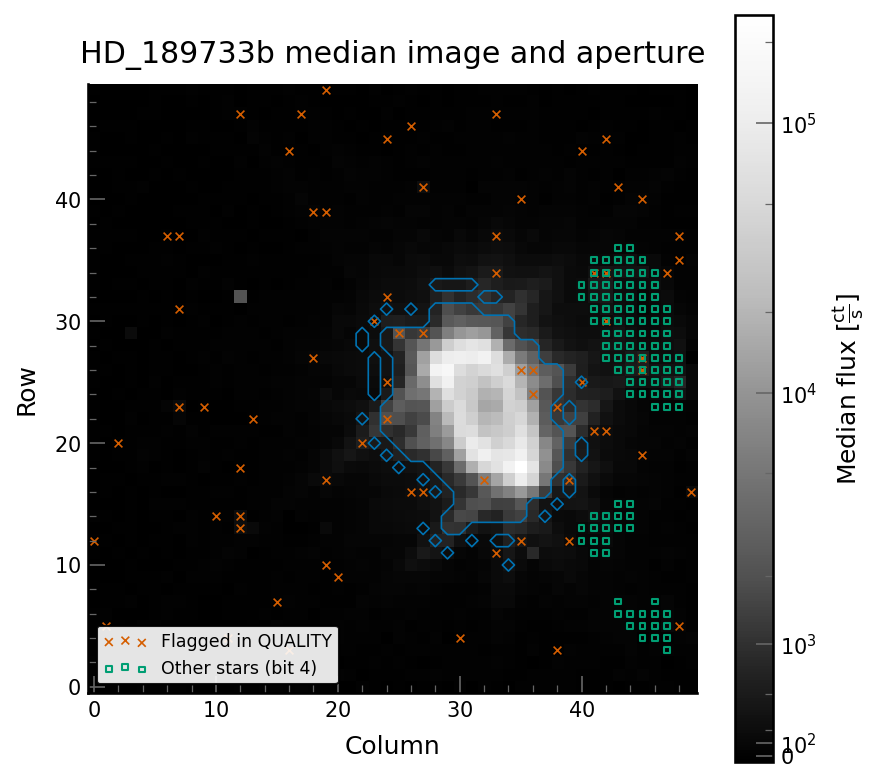

In [5]:
fig, ax = plt.subplots(figsize=(6, 5.5))
image = ax.imshow(
    median_image, cmap="Greys_r", interpolation="nearest",
    norm=AsinhNorm(linear_width=5 * np.std(median_image[~target]),
                   vmin=np.percentile(median_image, 1),
                   vmax=median_image.max()),
)
fig.colorbar(image, ax=ax, label=f"Median flux [{unit.to_string('latex')}]")
ax.contour(target, levels=[0.5], colors="#0072B2", linewidths=0.8)
rows_flagged, cols_flagged = np.where(flagged)
rows_other, cols_other = np.where(other_stars)
ax.scatter(cols_flagged, rows_flagged, s=14, marker="x", color="#D55E00",
           label="Flagged in QUALITY")
ax.scatter(cols_other, rows_other, s=8, marker="s", facecolors="none",
           edgecolors="#009E73", label="Other stars (bit 4)")
ax.set(title=f"{header['TARG_ID']} median image and aperture",
       xlabel="Column", ylabel="Row")
ax.legend(loc="lower left", fontsize="small")
plt.show()

## Centroid and pointing

The flux-weighted centroid of the target in each co-add, in detector pixels, compared with the target position that pandora-fits predicts from the spacecraft pointing (`VECTORS` `posx`, `posy`). Both are shown relative to their medians.

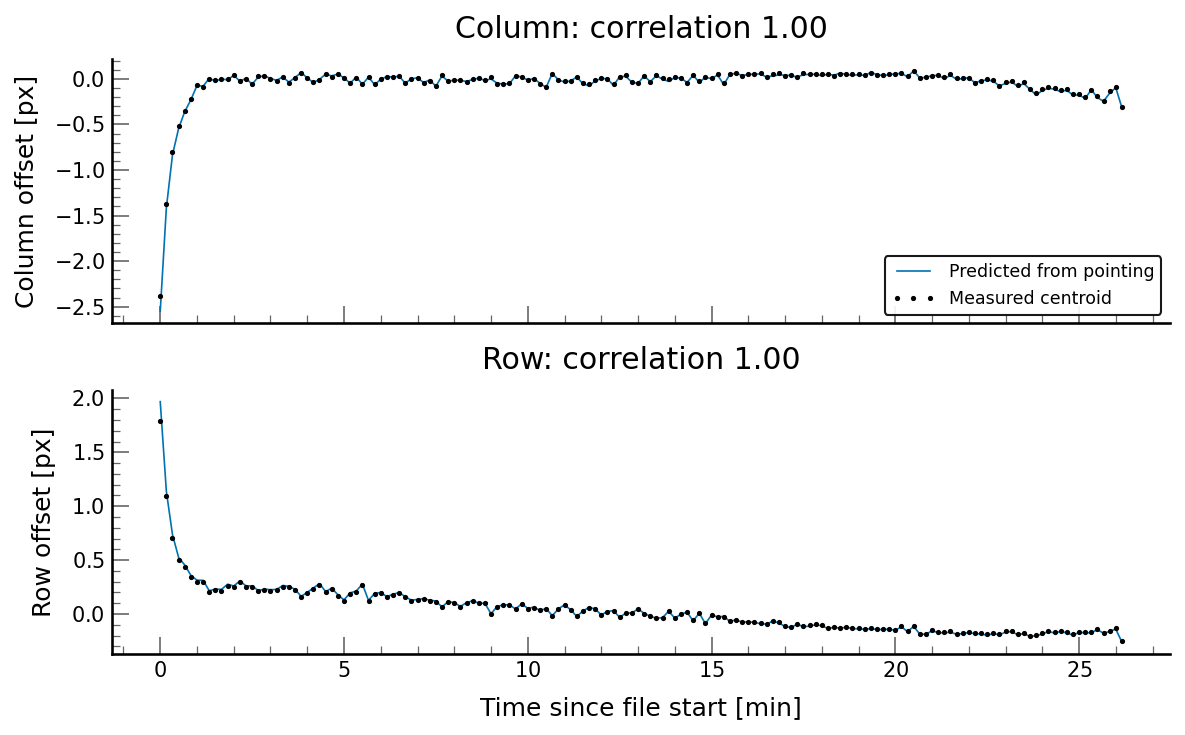

In [6]:
row_index, column_index = np.mgrid[:nrows, :ncols]
weights = np.where(target, cube, 0)
total = weights.sum(axis=(1, 2))
centroid_column = (weights * column_index).sum(axis=(1, 2)) / total
centroid_row = (weights * row_index).sum(axis=(1, 2)) / total
column_offset = centroid_column - np.median(centroid_column)
row_offset = centroid_row - np.median(centroid_row)
vectors = hdulist["VECTORS"].data

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, measured, predicted, label in [
    (axes[0], column_offset, vectors["posx"], "Column"),
    (axes[1], row_offset, vectors["posy"], "Row"),
]:
    ax.plot(time_minutes, predicted - np.nanmedian(predicted),
            color="#0072B2", label="Predicted from pointing")
    ax.plot(time_minutes, measured, ".", color="k", markersize=3,
            label="Measured centroid")
    agreement = np.corrcoef(measured, predicted)[0, 1]
    ax.set(ylabel=f"{label} offset [px]",
           title=f"{label}: correlation {agreement:.2f}")
axes[0].legend(loc="lower right", fontsize="small")
axes[1].set(xlabel="Time since file start [min]")
plt.show()

## Frame flags and decorrelation

Co-adds in the first `SETTLE_MINUTES` and co-adds with the centroid more than `MAX_OFFSET_PIXELS` from its median are flagged. The remaining relative flux $f$ is fitted with

$$f = c_0 + c_1 t + c_2 \Delta x + c_3 \Delta y + c_4 \Delta x^2 + c_5 \Delta y^2 + c_6 \Delta x \Delta y,$$

where $t$ is the time and $\Delta x$, $\Delta y$ the centroid offsets, iterating to flag outliers beyond `OUTLIER_SIGMA`. The decorrelated light curve is $f$ divided by the model without the constant. **A signal in time (a transit, a flare) inside the file can be partly absorbed by the time trend;** for transits, fit the trend over a whole visit together with a transit model (see `03_visit_analysis.ipynb`).

Flagged: 13 settling, 0 off target, 0 outliers; 145 of 158 kept


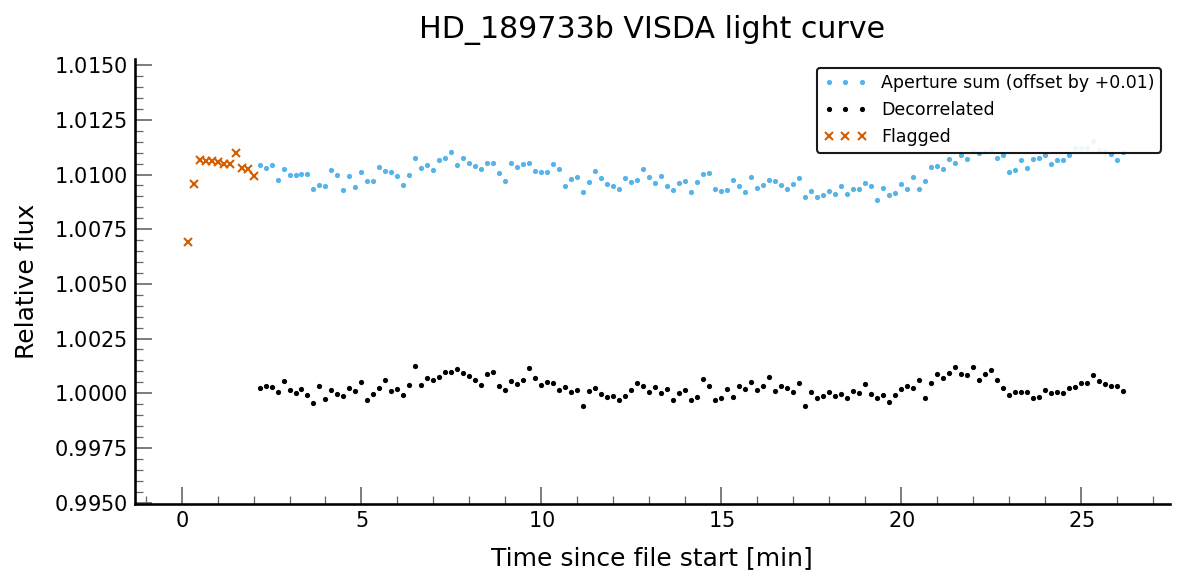

In [7]:
offset = np.hypot(column_offset, row_offset)
settling = time_minutes < SETTLE_MINUTES
off_target = offset > MAX_OFFSET_PIXELS
relative = flux / np.median(flux[~settling & ~off_target])

design = np.vstack([
    np.ones(ncoadds), time_minutes, column_offset, row_offset,
    column_offset**2, row_offset**2, column_offset * row_offset,
]).T
use = ~settling & ~off_target
for _ in range(5):
    coefficients, *_ = np.linalg.lstsq(design[use], relative[use],
                                       rcond=None)
    model = design @ coefficients
    residual = relative - model
    scatter = 1.4826 * np.median(np.abs(residual[use]))
    outlier = ~settling & ~off_target & (
        np.abs(residual) > OUTLIER_SIGMA * scatter
    )
    use = ~settling & ~off_target & ~outlier
decorrelated = relative / model * coefficients[0]

print(f"Flagged: {settling.sum()} settling, {(off_target & ~settling).sum()}"
      f" off target, {outlier.sum()} outliers; {use.sum()} of {ncoadds} kept")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(time_minutes[use], relative[use] + 0.01, ".", color="#56B4E9",
        markersize=3, label="Aperture sum (offset by +0.01)")
ax.plot(time_minutes[use], decorrelated[use], ".", color="k",
        markersize=3, label="Decorrelated")
ax.plot(time_minutes[~use], relative[~use] + 0.01, "x", color="#D55E00",
        markersize=4, label="Flagged")
ax.set(xlabel="Time since file start [min]", ylabel="Relative flux",
       title=f"{header['TARG_ID']} VISDA light curve",
       ylim=np.percentile(relative[use], [0.5, 99.5]) + [-0.004, 0.014])
ax.legend(loc="upper right", fontsize="small")
plt.show()

## Precision

The expected scatter of one co-add comes from the photon noise of the star and of the background in the aperture, and from the read noise of the `FRMPCOAD` reads summed in each co-add. The read noise of a single read, $\sigma_\mathrm{read}$, is pandoraref's `get_readnoise(1)` in DN; a co-add sums `FRMPCOAD` reads, so its read-noise variance per pixel is `FRMPCOAD` $\sigma_\mathrm{read}^2$.

Binning the light curve shows whether the noise averages down as white noise ($\propto 1/\sqrt{N}$) or flattens because of correlated (red) noise.

Expected per co-add: 180 ppm
Measured per co-add: 388 ppm after decorrelation (2.15 x expected; 608 ppm before)


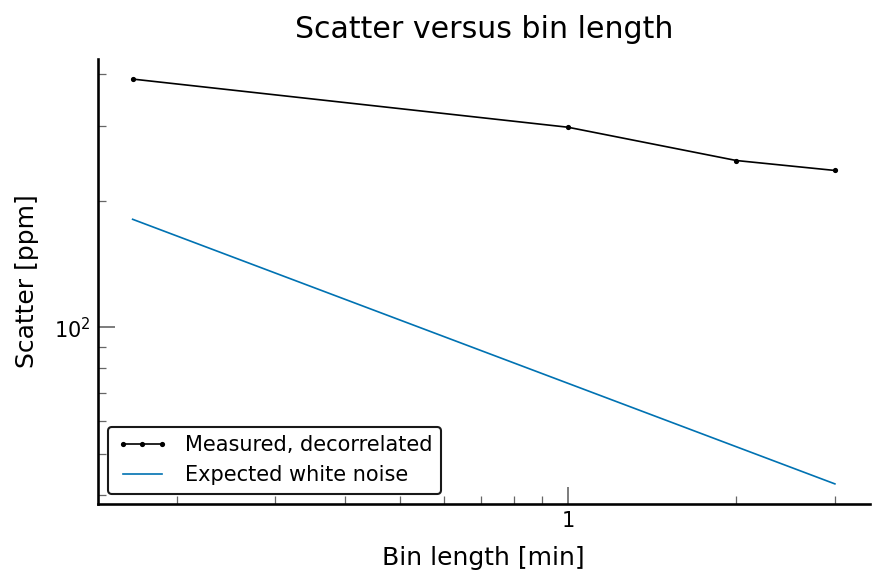

In [8]:
reference = hdulist.reference
gain = reference.get_gain().to(u.electron / u.DN).value
read_noise = reference.get_readnoise(1).value  # DN per read
median_flux = np.median(flux[use])
variance = (
    (median_flux + target.sum() * np.median(background))
    / (gain * exptime[0])
    + target.sum() * frames_per_coadd * read_noise**2 / exptime[0] ** 2
)
expected = np.sqrt(variance) / median_flux

kept = decorrelated[use] - coefficients[0]
cadence_minutes = np.median(np.diff(time_minutes))
rows = []
bin_sizes = [1] + [int(round(m / cadence_minutes)) for m in BIN_MINUTES]
for nbin in sorted(set(bin_sizes)):
    if nbin < 1 or kept.size // nbin < MIN_BINS:
        continue
    binned = kept[: (kept.size // nbin) * nbin].reshape(-1, nbin).mean(axis=1)
    rows.append((nbin * cadence_minutes, np.std(binned), nbin))
bin_minutes, binned_rms, nbins = np.array(rows).T
print(f"Expected per co-add: {expected * 1e6:.0f} ppm")
print(f"Measured per co-add: {binned_rms[0] * 1e6:.0f} ppm after "
      f"decorrelation ({binned_rms[0] / expected:.2f} x expected; "
      f"{np.std(relative[use]) * 1e6:.0f} ppm before)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(bin_minutes, binned_rms * 1e6, "o-", color="k",
        label="Measured, decorrelated")
ax.plot(bin_minutes, expected / np.sqrt(nbins) * 1e6, color="#0072B2",
        label="Expected white noise")
ax.set(xscale="log", yscale="log", xlabel="Bin length [min]",
       ylabel="Scatter [ppm]", title="Scatter versus bin length")
ax.legend()
plt.show()

## Background

The `BACKGROUND` extension: one value per co-add, the median of the aperture-free, unflagged pixels with sources clipped. Changes in the background (scattered earthshine near the end of an orbit, for example) are a common source of systematics.

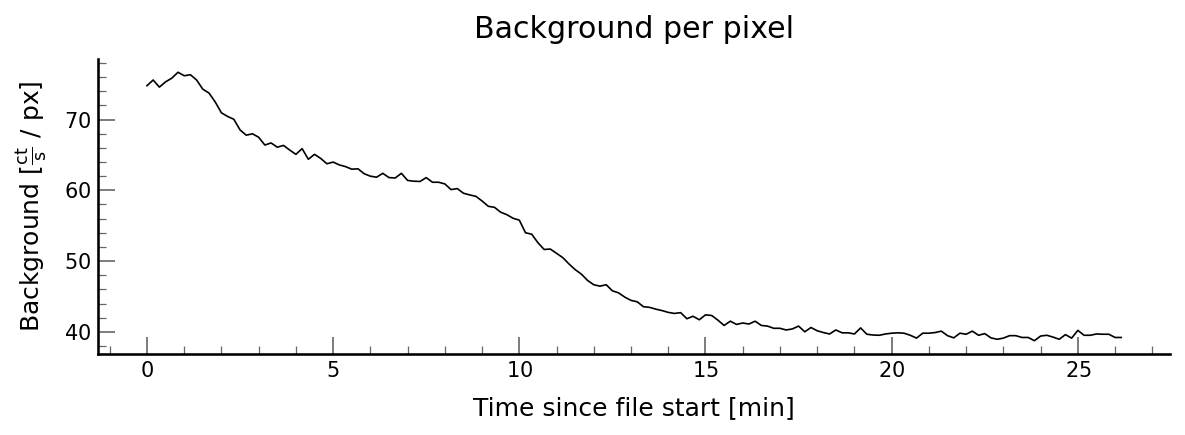

In [9]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(time_minutes, background, color="k")
ax.set(xlabel="Time since file start [min]",
       ylabel=f"Background [{unit.to_string('latex')} / px]",
       title="Background per pixel")
plt.show()

## Caveats

These come from the Level 2 products, not from this notebook:

- **Bias.** pandora-fits subtracts the pandoraref bias map times `FRMPCOAD`. In pandora-fits 0.9.0 and pandoraref 2.9.1 that map is offset by 4 columns from the data, which adds a fixed pattern of about 10 ct/s per pixel to the ROI. Within a file this is constant, so relative photometry is unaffected, but it changes from file to file as the ROI moves, and it can make the background negative in faint fields.
- **`TIME`** is the start of each co-add; the middle is `TIME + EXPTIME / 2`.
- **`posx`, `posy`** come from a WCS whose plate scale is about 0.6% too small in pandoraref 2.9.1; this matters for stars far from the ROI center, not for the target.
- No dark or flat-field correction is applied at Level 2.